# 第1回 データ理解（EDA）

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、値を変えて何度か実行してみてください。

**この回のゴール**

1. MMMで使うデータの形（どんな列があるか）を知る
2. 売上の季節性と、チャネルごとの広告費の使い方をつかむ
3. 「売上と広告費の相関を見るだけでは、広告の効果は分からない」ことを、データで確かめる

**所要時間**：30〜45分。重い計算はありません。

**データについて**：PyMC-Marketing のケーススタディで使われている公開学習用データです（週次、209週）。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/01-eda>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. データを読み込む

1行が1週間です。まず大きさ・期間・欠損を確認します。

In [3]:
df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

print("行数（週の数）:", len(df))
print("列数:", df.shape[1])
print("期間:", df["wk_strt_dt"].min().date(), "〜", df["wk_strt_dt"].max().date())
print("欠損の数:", int(df.isna().sum().sum()))
df.head(3)

行数（週の数）: 209
列数: 80
期間: 2014-08-03 〜 2018-07-29
欠損の数: 0


,wk_strt_dt,yr_nbr,qtr_nbr,prd,wk_nbr,wk_in_yr_nbr,mdip_dm,mdip_inst,mdip_nsp,mdip_auddig,...,seas_prd_12,seas_week_40,seas_week_41,seas_week_42,seas_week_43,seas_week_44,seas_week_45,seas_week_46,seas_week_47,seas_week_48
0,2014-08-03,2014,3,7,1,27,4863885,29087520,2421933,692315,...,0,0,0,0,0,0,0,0,0,0
1,2014-08-10,2014,3,7,2,28,20887502,8345120,3984494,475810,...,0,0,0,0,0,0,0,0,0,0
2,2014-08-17,2014,3,7,3,29,11097724,17276800,1846832,784732,...,0,0,0,0,0,0,0,0,0,0


### 列の種類

列が80個ありますが、名前の先頭（接頭辞）で役割が分かれています。種類ごとに数えます。

In [4]:
prefix_meaning = {
    "mdsp_": "メディア費用（spend）",
    "mdip_": "メディアのインプレッション（表示回数）",
    "hldy_": "祝日フラグ（その週に祝日があれば1）",
    "seas_": "季節フラグ",
    "me_": "マクロ経済指標",
    "mrkdn_": "値引き",
    "st_ct": "店舗数",
    "sales": "売上（目的変数）",
    "wk_strt_dt": "週の開始日",
}
rows = []
for prefix, meaning in prefix_meaning.items():
    cols = [c for c in df.columns if c.startswith(prefix)]
    rows.append({"接頭辞": prefix, "意味": meaning, "列の数": len(cols), "例": ", ".join(cols[:2])})
pd.DataFrame(rows)

,接頭辞,意味,列の数,例
0,mdsp_,メディア費用（spend）,10,"mdsp_dm, mdsp_inst"
1,mdip_,メディアのインプレッション（表示回数）,13,"mdip_dm, mdip_inst"
2,hldy_,祝日フラグ（その週に祝日があれば1）,22,"hldy_Black Friday, hldy_Christmas Day"
3,seas_,季節フラグ,19,"seas_prd_1, seas_prd_2"
4,me_,マクロ経済指標,2,"me_ics_all, me_gas_dpg"
5,mrkdn_,値引き,2,"mrkdn_valadd_edw, mrkdn_pdm"
6,st_ct,店舗数,1,st_ct
7,sales,売上（目的変数）,1,sales
8,wk_strt_dt,週の開始日,1,wk_strt_dt


**大事な区別**

- **目的変数**：説明したいもの。ここでは `sales`（売上）
- **説明変数**：売上を説明するもの。広告費、祝日、季節、値引きなど

MMMは「売上を、説明変数の足し算で説明する」モデルです。この回では、広告費（`mdsp_`）を中心に見ます。

広告費の列は10チャネルあります。略称が分かりにくいので、日本語の名前に置き換えます。

In [5]:
channel_names = {
    "mdsp_dm": "DM",
    "mdsp_inst": "折込",
    "mdsp_nsp": "新聞",
    "mdsp_auddig": "デジタル音声",
    "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV",
    "mdsp_viddig": "デジタル動画",
    "mdsp_so": "ソーシャル",
    "mdsp_on": "ディスプレイ",
    "mdsp_sem": "検索",
}
spend = df[list(channel_names)].rename(columns=channel_names)   # 広告費だけの表
channels = list(spend.columns)
spend.head(3)

,DM,折込,新聞,デジタル音声,ラジオ,TV,デジタル動画,ソーシャル,ディスプレイ,検索
0,678410.26,129759.66,507635.16,2700.69,254134.14,216725.59,45397.90,0.0,61364.75,355954.51
1,661097.71,70355.33,625719.37,5039.35,106602.98,108919.26,2903.36,0.0,132643.90,336306.72
2,1874338.43,107720.37,277532.61,2610.93,59011.42,74032.19,8110.48,0.0,76741.27,344787.96


## 2. 売上を見る

### 2-1. 売上の推移

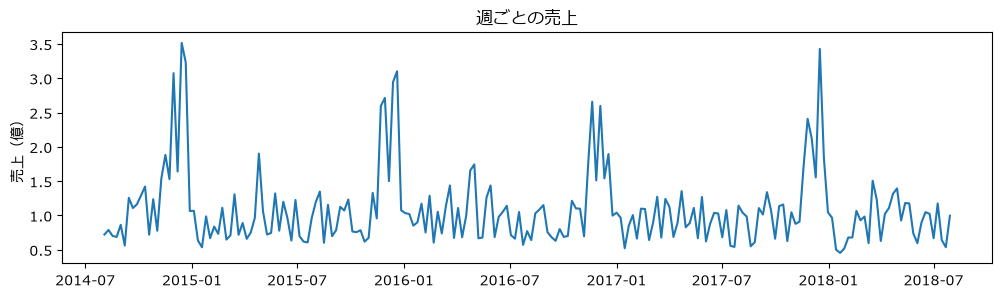

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(df["wk_strt_dt"], df["sales"] / 1e8)
ax.set_ylabel("売上（億）")
ax.set_title("週ごとの売上");

**読み方**：毎年、年末に大きな山があります。月ごとに平均して確かめます。

### 2-2. 月別の週平均売上

12月: 2.06 億 / 11月: 1.64 億 / 1月: 0.83 億
12月は1月の 2.5 倍


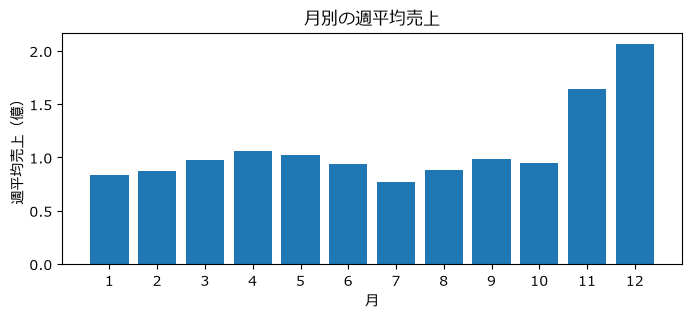

In [7]:
df["month"] = df["wk_strt_dt"].dt.month
monthly = df.groupby("month")["sales"].mean() / 1e8

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(monthly.index, monthly.values)
ax.set_xticks(range(1, 13))
ax.set_xlabel("月")
ax.set_ylabel("週平均売上（億）")
ax.set_title("月別の週平均売上")

print("12月:", round(monthly[12], 2), "億 / 11月:", round(monthly[11], 2), "億 / 1月:", round(monthly[1], 2), "億")
print("12月は1月の", round(monthly[12] / monthly[1], 1), "倍")

In [8]:
# 売上が大きかった週 上位5
top = df.nlargest(5, "sales")[["wk_strt_dt", "sales"]].copy()
top["sales"] = (top["sales"] / 1e8).round(2)
top

,wk_strt_dt,sales
19,2014-12-14,3.52
176,2017-12-17,3.43
20,2014-12-21,3.23
72,2015-12-20,3.10
17,2014-11-30,3.07


**読み方**：12月の売上は1月の約2.5倍。売上上位の週は12月中旬に集中しています。この会社の売上には**強い季節性**があります。

### 2-3. 季節性を説明しそうな列

「12月に売上が高い理由」を説明できそうな列を探します。祝日フラグの列を一覧にします。

In [9]:
holiday_cols = [c for c in df.columns if c.startswith("hldy_")]
print("祝日フラグの数:", len(holiday_cols))
print([c.replace("hldy_", "") for c in holiday_cols])

祝日フラグの数: 22
['Black Friday', 'Christmas Day', 'Christmas Eve', 'Columbus Day', 'Cyber Monday', 'Day after Christmas', 'Easter', "Father's Day", 'Green Monday', 'July 4th', 'Labor Day', 'MLK', 'Memorial Day', "Mother's Day", 'NYE', "New Year's Day", 'Pre Thanksgiving', 'Presidents Day', 'Prime Day', 'Thanksgiving', "Valentine's Day", 'Veterans Day']


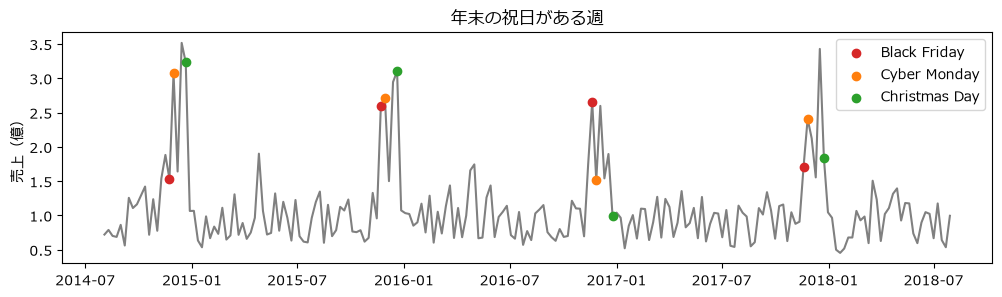

In [10]:
# 年末の祝日がある週に印をつけて、売上と重ねる
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(df["wk_strt_dt"], df["sales"] / 1e8, color="gray")
for col, color in [("hldy_Black Friday", "C3"), ("hldy_Cyber Monday", "C1"), ("hldy_Christmas Day", "C2")]:
    weeks = df[df[col] == 1]
    ax.scatter(weeks["wk_strt_dt"], weeks["sales"] / 1e8, color=color, label=col.replace("hldy_", ""), zorder=3)
ax.set_ylabel("売上（億）")
ax.set_title("年末の祝日がある週")
ax.legend();

**読み方**：Black Friday・Cyber Monday・Christmas の週は、売上の山の近くにあります。
MMMでは、こうした祝日フラグを説明変数に入れて「祝日による売上」と「広告による売上」を分けます。

> **よくある間違い**：「売上が高い理由」として `sales` を挙げてしまうこと。`sales` は説明される側（目的変数）なので、理由にはなりません。

## 3. 広告費を見る

### 3-1. チャネル別の総費用と割合

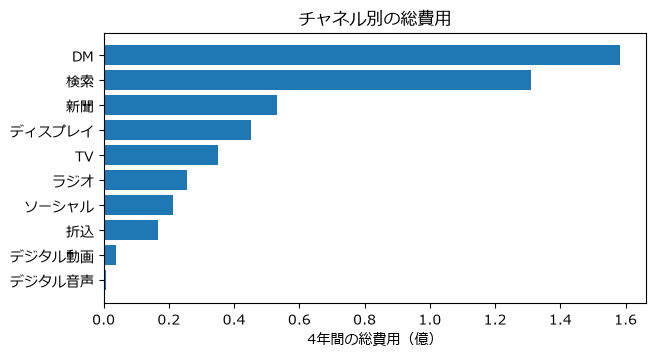

In [11]:
total = spend.sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(total.index, total.values / 1e8)
ax.set_xlabel("4年間の総費用（億）")
ax.set_title("チャネル別の総費用");

In [12]:
share = (spend.sum() / spend.sum().sum()).sort_values(ascending=False)
print("上位2チャネルの合計:", f"{share.iloc[:2].sum():.1%}")
(share * 100).round(1).to_frame("費用の割合（%）")

上位2チャネルの合計: 58.9%


,費用の割合（%）
DM,32.3
検索,26.7
新聞,10.8
ディスプレイ,9.2
TV,7.2
ラジオ,5.2
ソーシャル,4.3
折込,3.4
デジタル動画,0.8
デジタル音声,0.2


**読み方**

- DM と検索の2チャネルで、広告費全体の約6割を占めています
- デジタル音声とデジタル動画は1%未満です

**ケーススタディ1のモデルは7チャネル**で、デジタル音声・デジタル動画・検索の3つを使いません。
本家のノートブックには理由の説明がないので、以下は私の解釈です。

- デジタル音声・デジタル動画：費用が小さすぎて、効果をデータから見分けられない
- 検索：需要が高い週ほど検索する人が増え、検索広告の費用も増える。「広告 → 売上」だけでなく「売上（需要）→ 広告費」の向きが混ざる

### 3-2. 広告費の使い方（時期）

費用の多い DM と、TV の推移を比べます。

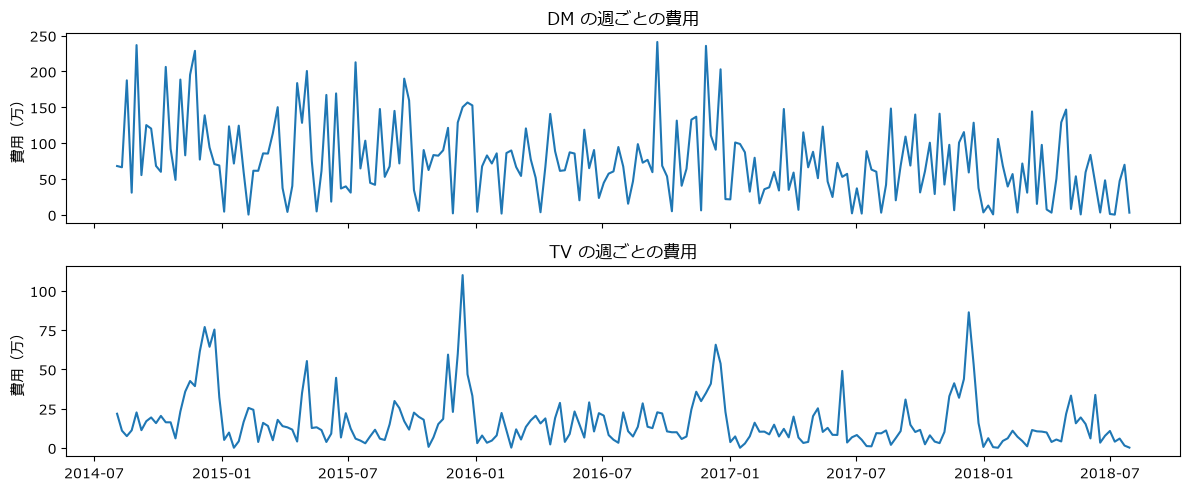

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, ch in zip(axes, ["DM", "TV"]):
    ax.plot(df["wk_strt_dt"], spend[ch] / 1e4)
    ax.set_ylabel("費用（万）")
    ax.set_title(f"{ch} の週ごとの費用")
plt.tight_layout()

**読み方**

- **DM**：週ごとの上下は大きいが、特定の季節には偏っていない
- **TV**：年末に集中して出している

この「出し方の違い」が、次の章で大きな意味を持ちます。

## 4. 相関を見る ― そして、だまされる

「売上と一緒に動く広告ほど、効いているはず」と考えて、広告費と売上の相関係数を出してみます。

> 相関係数：2つの数字が一緒に動く度合い。1に近いほど「片方が増えるともう片方も増える」。0は関係なし。

TV        0.66
検索        0.59
折込        0.52
ディスプレイ    0.48
デジタル動画    0.46
新聞        0.42
デジタル音声    0.37
ソーシャル     0.33
ラジオ       0.28
DM        0.15
dtype: float64

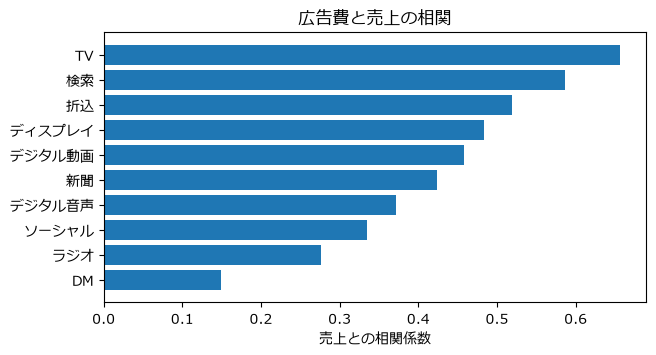

In [14]:
corr = spend.corrwith(df["sales"]).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(corr.index, corr.values)
ax.set_xlabel("売上との相関係数")
ax.set_title("広告費と売上の相関")

corr.sort_values(ascending=False).round(2)

**素直に読むと**：TVが最も高く（0.66）、いちばん費用を使っているDMが最も低い（0.15）。

「TVは効いている。DMは効いていないから減らそう」と言いたくなります。**本当でしょうか。**

### 4-1. 散布図で確かめる

TV費用と売上の散布図を、11〜12月とそれ以外で色分けします。

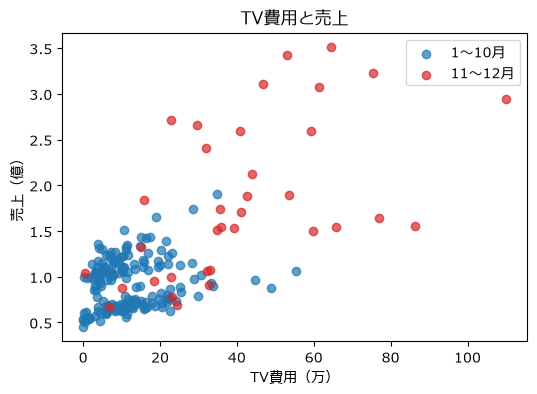

In [15]:
is_peak = df["month"].isin([11, 12])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(spend["TV"][~is_peak] / 1e4, df["sales"][~is_peak] / 1e8, label="1〜10月", alpha=0.7)
ax.scatter(spend["TV"][is_peak] / 1e4, df["sales"][is_peak] / 1e8, label="11〜12月", alpha=0.7, color="C3")
ax.set_xlabel("TV費用（万）")
ax.set_ylabel("売上（億）")
ax.set_title("TV費用と売上")
ax.legend();

**読み方**：右上にある点（TV費用も売上も大きい週）は、ほとんどが11〜12月です。
「TVを出したから売れた」のか、「年末だから売れた（そして年末だからTVも出した）」のか、この図では区別できません。

### 4-2. 11〜12月を除いて相関を出し直す

In [16]:
corr_all = spend.corrwith(df["sales"])
corr_offpeak = spend[~is_peak].corrwith(df["sales"][~is_peak])
peak_ratio = spend[is_peak].mean() / spend[~is_peak].mean()     # 11〜12月は、ふだんの何倍出しているか

compare = pd.DataFrame({
    "費用の割合（%）": (share * 100).round(1),
    "売上との相関": corr_all.round(2),
    "11〜12月を除いた相関": corr_offpeak.round(2),
    "11〜12月の費用倍率": peak_ratio.round(2),
}).sort_values("売上との相関", ascending=False)
compare

,費用の割合（%）,売上との相関,11〜12月を除いた相関,11〜12月の費用倍率
TV,7.2,0.66,0.20,3.47
検索,26.7,0.59,0.15,2.78
折込,3.4,0.52,0.12,2.51
ディスプレイ,9.2,0.48,0.20,1.96
デジタル動画,0.8,0.46,0.09,2.49
新聞,10.8,0.42,-0.01,2.98
デジタル音声,0.2,0.37,0.02,1.99
ソーシャル,4.3,0.33,0.09,2.38
ラジオ,5.2,0.28,0.02,1.52
DM,32.3,0.15,0.01,1.48


**読み方**

- TV の相関は 0.66 → 0.20 に下がりました。相関の大部分は「年末」が作っていたことになります
- TV は11〜12月に、ふだんの約3.5倍の費用を出しています。売上が増える時期に広告も増やしているので、効果がなくても相関は高く出ます
- DM は季節への偏りが小さい（11〜12月でも1.5倍）ので、「年末による水増し」が少なく、相関が低く出ます。**「効いていない」とは言えません**
- 11〜12月を除くと、どのチャネルも相関は0.2以下で、大きな差はなくなります

### 4-3. これが「交絡」

売上と広告費の両方に影響する第三の要因（ここでは**季節**）があると、広告に効果がなくても相関が生まれます。これを**交絡**といいます。

```
        季節（年末）
        ↙        ↘
   広告費を増やす    売上が増える
        └── ？ ──→
```

知りたいのは下の「？」の矢印（広告 → 売上）の大きさです。相関係数は、上の2本の矢印の影響も一緒に拾ってしまいます。

**だからMMMが必要です。** MMMは、季節・祝日・トレンドなどを説明変数に入れて切り分けたうえで、広告の効果を推定します。

## 5. 🧪 実験：ほかの月・ほかのチャネルで確かめる

下のセルの `CHANNEL` と `EXCLUDE_MONTHS` を変えて実行してみてください。

検索：全期間の相関 = 0.59
検索：[11, 12]月を除いた相関 = 0.15


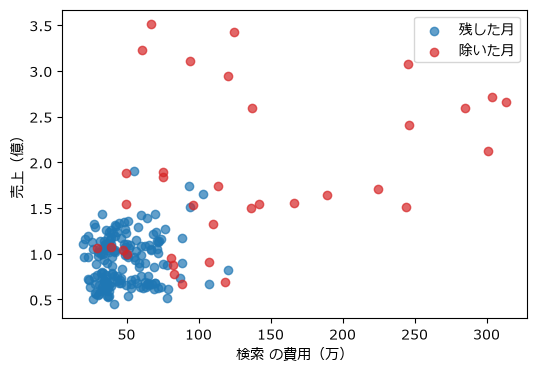

In [17]:
CHANNEL = "検索"            # チャネル名を変える（例："新聞"、"ディスプレイ"、"DM"）
EXCLUDE_MONTHS = [11, 12]   # 除く月を変える（例：[12]、[10, 11, 12]）

keep = ~df["month"].isin(EXCLUDE_MONTHS)
print(f"{CHANNEL}：全期間の相関 = {spend[CHANNEL].corr(df['sales']):.2f}")
print(f"{CHANNEL}：{EXCLUDE_MONTHS}月を除いた相関 = {spend[CHANNEL][keep].corr(df['sales'][keep]):.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(spend[CHANNEL][keep] / 1e4, df["sales"][keep] / 1e8, label="残した月", alpha=0.7)
ax.scatter(spend[CHANNEL][~keep] / 1e4, df["sales"][~keep] / 1e8, label="除いた月", alpha=0.7, color="C3")
ax.set_xlabel(f"{CHANNEL} の費用（万）")
ax.set_ylabel("売上（億）")
ax.legend();

## 6. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　DMの相関は0.15で、10チャネル中いちばん低い値でした。上司や経営層に「DMは効いていないので、やめましょう」と提案してよいでしょうか。

<details>
<summary>答えを見る</summary>

いけません。理由は2つあります。

1. ほかのチャネルの相関は「年末に広告を増やしている」ことで水増しされています。DMは季節への偏りが小さいので、水増しが少ないだけです。11〜12月を除けば、どのチャネルも相関は0.2以下で、DMだけが特に低いとは言えません
2. DMは、届いてから購入までに時間がかかります。「同じ週の費用と売上」の相関では、遅れて出る効果を拾えません（次回の adstock で扱います）

効果を知るには、季節を切り分け、遅れて出る効果も考えに入れたモデル（MMM）が必要です。

</details>

**課題2**　5章のセルで `CHANNEL = "検索"` のまま実行すると、相関は 0.59 → 0.15 に下がります。
検索広告には、季節のほかにもう1つ、相関を高く見せる理由があります。何でしょうか。

<details>
<summary>答えを見る</summary>

「売上（需要）→ 広告費」という逆向きの関係です。
商品を欲しい人が増えると検索が増え、クリックが増え、検索広告の費用も自動的に増えます。広告が需要を作ったのではなく、需要が広告費を増やしています。
このため検索広告は、費用対効果が実際より良く見えやすいチャネルです。

</details>

**課題3**　自分の会社、または身近なお店や商品を1つ思い浮かべてください。そこで「売上と広告費の両方を動かす第三の要因」になりそうなものを3つ挙げてください。

<details>
<summary>答えの例を見る</summary>

- セール・キャンペーン（セール中は売上も広告も増える）
- 新商品の発売（発売時に広告を集中させる）
- 季節・天候・連休（需要が動く時期に合わせて広告を出す）
- 展示会や決算期（企業向けの商売では、受注も販促も集中する）
- 競合の動き（競合の値下げに対抗して広告を増やす）

MMMを始める前に、こうした要因を洗い出して、その記録（いつ、何があったか）を集めておくことが重要です。

</details>

## 7. まとめ

- データは週次209週。売上（目的変数）と、広告費・祝日・季節など（説明変数）でできている
- 売上には強い季節性がある（12月は1月の約2.5倍）
- 広告費は DM と検索で約6割。DMは季節に偏らず、TVは年末集中と、出し方が違う
- 相関だけを見ると「TVは効く、DMは効かない」に見える。しかし11〜12月を除くと、TVの相関は 0.66 → 0.20 に下がる
- 季節のような第三の要因が相関を作ることを**交絡**という。**相関 ≠ 効果**
- MMMは、季節や祝日を切り分けたうえで広告の効果を推定する

**自分の会社のデータで、まず確かめたい問い**

- 費用の大きい上位のチャネルについて、効果を確かめたことがあるか
- 繁忙期に広告を増やしていないか。その時期の売上増を、広告のおかげと言い切れるか
- 検索広告の費用対効果が、良く見えすぎていないか（買う気のある人ほど検索するので、広告がなくても売れた分が混ざりやすい）

**次回（第2回）**：広告ならではの2つの性質、adstock（残存効果）と saturation（頭打ち）を、自分で関数を作って理解します。